In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt

import hnn_core
from hnn_core.params import _short_name

from hnn_core import  simulate_dipole, read_dipole, MPIBackend, jones_2009_model


from urllib.request import urlretrieve

exp_dpl = read_dipole('/Users/katharinaduecker/Documents/projects_brown/hnn-data/MEG_detection_data/S1_SupraT.txt')

from hnn_core.dipole import _rmse

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'



In [2]:
from hnn_core.hnn_io import read_network_configuration
net = read_network_configuration('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/compare_jones2009/optimized_2.0_ERPYesSupraT.json')

In [6]:
tstop = exp_dpl.times[-1]
scale_factor = 3000
smooth_window_len = 30

depths = list(list(range(-100,2400,400)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos, method='lsa')

#vnet = jones_2009_model()

# synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
#                      'L5_basket': 1., 'L5_pyramidal': 1.}


# net.add_evoked_drive('evprox1',
#                         mu=19.64,
#                         sigma=2.52,
#                         numspikes=1,
#                         location='proximal',
#                         weights_ampa={"L2_basket": 0.13868736044532387,
#                                         "L2_pyramidal": 0.21032866390593508,
#                                         "L5_basket": 0.27777906242116746,
#                                         "L5_pyramidal": 0.04799989879291564},
#                         weights_nmda={"L2_basket": 0.06270429447213936,
#                                     "L2_pyramidal": 0.08926994684925202,
#                                     "L5_basket": 0.08208037565020894,
#                                     "L5_pyramidal": 0.04948245978299645},
#                         synaptic_delays=synaptic_delays_p, event_seed=2, cell_specific=True)


# # Distal
# synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

# net.add_evoked_drive('evdist',
#                         mu=65.69,
#                         sigma=3.81,
#                         numspikes=1,
#                         location='distal',
#                         weights_ampa={"L2_basket": 0.5911085138149106,
#                                     "L2_pyramidal": 1.2715372848380149,
#                                     "L5_pyramidal": 0.7313422149558968},
#                         weights_nmda={"L2_basket": 0.01722611258311317,
#                                     "L2_pyramidal": 0.12081641102681595,
#                                     "L5_pyramidal": 0.43075365866954696},
#                         synaptic_delays=synaptic_delays_d, event_seed=2, cell_specific=True)


# net.add_evoked_drive('evprox2',
#                     mu=90.53,
#                     sigma=10.38,
#                     numspikes=1,
#                     location='proximal',
#                     weights_ampa={"L2_basket": 0.012001705771547175,
#                                     "L2_pyramidal": 4.940529888142516,
#                                     "L5_basket": 0.08489658191921519,
#                                     "L5_pyramidal": 4.957398598001994},
#                     weights_nmda={"L2_basket": 0.004915222110236328,
#                 "L2_pyramidal": 0.07676408472410595,
#                 "L5_basket": 0.022539296276446432,
#                 "L5_pyramidal": 0.08310341625557321
#             },
#                     synaptic_delays=synaptic_delays_p, event_seed=2, cell_specific=True)
dpl = simulate_dipole(net, tstop=tstop, n_trials=1)[0]

dpl.scale(scale_factor).smooth(smooth_window_len)

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Applying Jones baseline correction


In [ ]:
import numpy as np
rmse = _rmse(dpl, exp_dpl,tstart=0,tstop=1000)

In [9]:
import numpy as np
from cmcrameri import cm
import matplotlib
step_cm = int(len(cm.hawaiiS.colors) / 19)
cm_neurons = np.array([[166,206,227], [31,120,180], [178,223,138],[51,160,44]])/255


cmap = matplotlib.colors.ListedColormap(cm_neurons)

col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cmap_lines = matplotlib.colors.ListedColormap(col_lines)
cmap_lines

def assign_color(gid):
    for cell_type, gid_range in net.gid_ranges.items():
        if cell_type in list(cell_type_colors.keys()):
            if gid in gid_range:
                return cell_type_colors[cell_type]

In [16]:
from hnn_core.extracellular import _get_laminar_z_coords

contact_labels, delta = _get_laminar_z_coords(net.rec_arrays['probe1'][0].positions)
new_lim = contact_labels[0:len(contact_labels):1]/1000

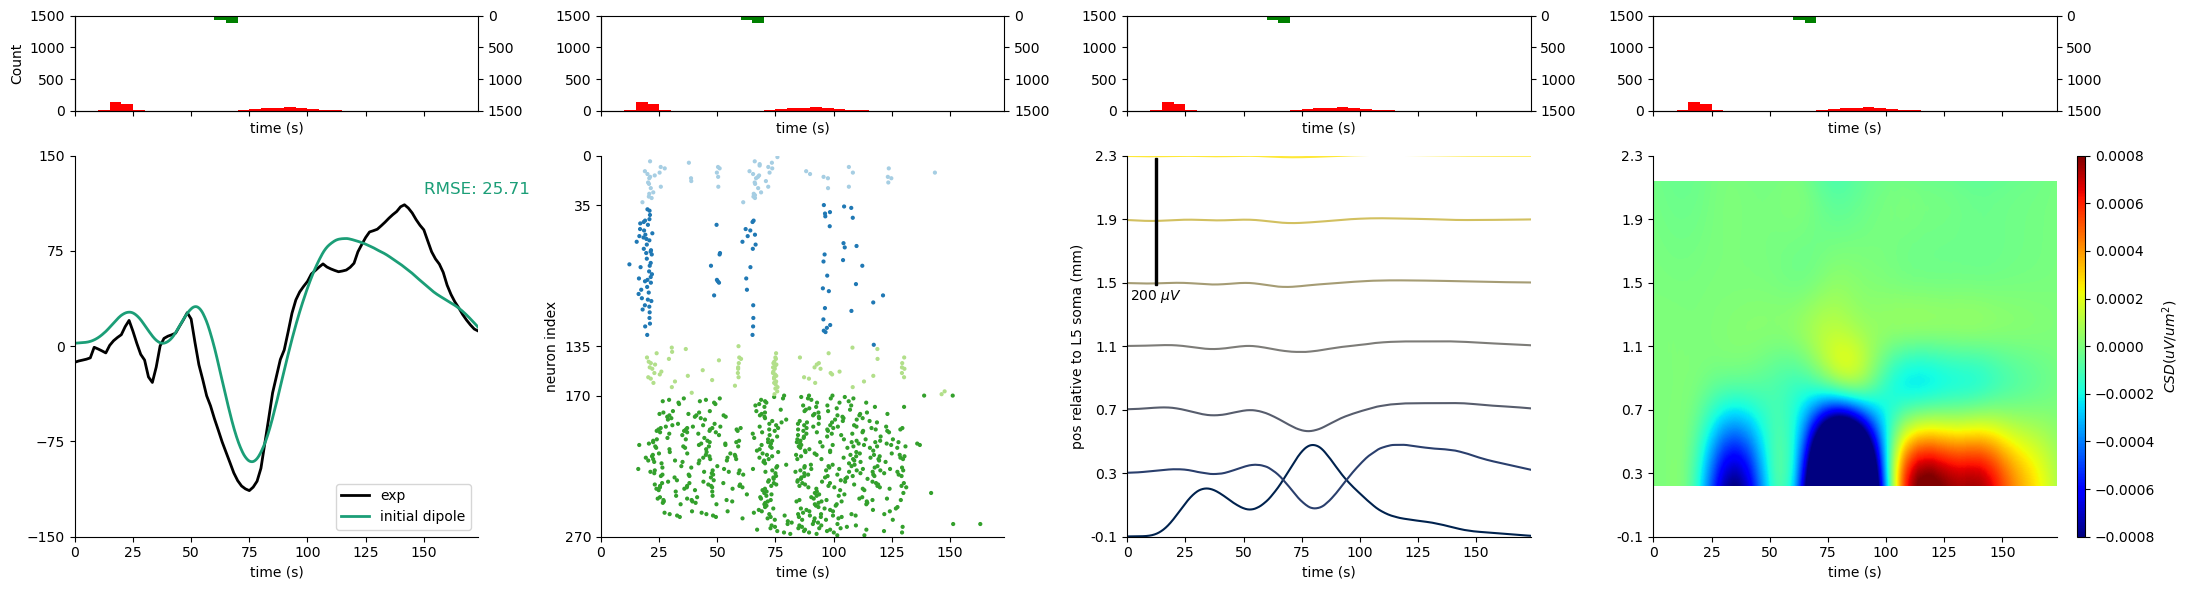

In [17]:
fig, ax = plt.subplots(2,4,figsize=(22,6), height_ratios=[0.25,1], sharex=True)

# drives
# proximal and distal histogram
spike_prox1 = np.array(net.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['evdist1']).reshape(-1,1)
spike_prox2 = np.array(net.cell_response.spike_times_by_type['evprox2']).reshape(-1,1)
bins = np.arange(0, tstop, 5)  # histogram bins

for i in range(4):
    ax[0,i].hist(spike_prox1, bins, color='r')
    ax[0,i].set_ylim([0, 1500])

    if i == 0:
        ax[0,i].set_ylabel('Count')
    ax[0,i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1500])
    ax1tw.invert_yaxis()

ax[1,0].plot(exp_dpl.times,exp_dpl.data['agg'], label='exp', color='k', linewidth=2)
ax[1,0].plot(dpl.times,dpl.data['agg'], label='initial dipole', color=col_lines[0], linewidth=2)

ax[1,0].text(150, 120, 'RMSE: %.2f' %rmse, fontsize=12, color=col_lines[0])

ax[1,0].set_ylim([-150, 150])
ax[1,0].set_yticks([-150, -75, 0, 75, 150])
ax[1,0].legend(loc='lower right')

# spiking
I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I]
cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
cell_type_colors = {'L2_basket': cmap.colors[0], 'L2_pyramidal': cmap.colors[1], 
               'L5_basket': cmap.colors[2], 'L5_pyramidal': cmap.colors[3]}

colors = [assign_color(gid) for gid in gids]

ax[1,1].scatter(times, gids, s=4, alpha=1., c=colors)
ax[1,1].set_ylabel('neuron index')
ax[1,1].set_xlim([0, 175])
ax[1,1].set_xlabel('time (ms)')
ax[1,1].set_ylim([0, 270])
ax[1,1].set_yticks([0, 35, 135, 170, 270])
ax[1,1].invert_yaxis()
ax[1,1].set_xticks(np.arange(0, 176, 25))
ax[1,1].set_xlim((0, 175))

net.rec_arrays['probe1'][0].smooth(smooth_window_len).plot_lfp(ax=ax[1,2], show=False, voltage_offset=100)
lfp_ticks = ax[1,2].get_yticks()
ax[1,2].set_yticks(np.linspace(lfp_ticks[0], lfp_ticks[-1], len(new_lim)))
ax[1,2].set_yticklabels(new_lim)
ax[1,2].set_ylabel('pos relative to L5 soma (mm)')
ax[1,2].set_ylim([lfp_ticks[0], lfp_ticks[-1]])

net.rec_arrays['probe1'][0].smooth(smooth_window_len).plot_csd(ax=ax[1,3], show=False, vmin=-0.0008, vmax=0.0008, )
csd_ticks = ax[1,3].get_yticks()
ax[1,3].set_yticks(np.linspace(csd_ticks[0], csd_ticks[-1], len(new_lim)))
ax[1,3].set_yticklabels(new_lim)
ax[1,3].set_ylabel('')
ax = ax.flatten()
for a in ax:
    a.set_xlabel('time (s)')
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'optim_hand_dpl.png'))
fig.savefig(os.path.join(pathfig,'optim_hand_dpl.pdf'))

fig.savefig(os.path.join(pathfig,'jones2009_optimized_2.0_ERPYesSupraT.png'), dpi=300, bbox_inches='tight')

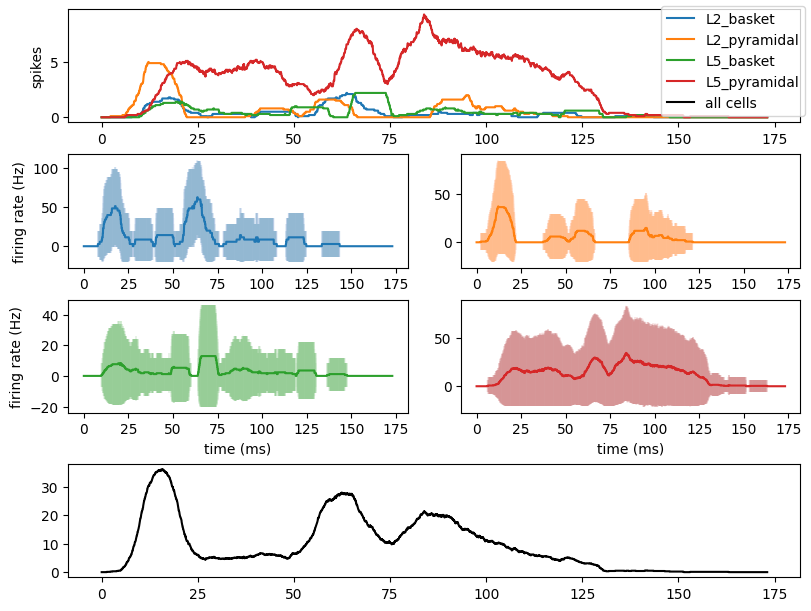

In [ ]:
import numpy as np
smooth_window_len = 10
fig = plt.figure(figsize=(8, 6), layout="constrained")
spec = fig.add_gridspec(4, 2)

ax0 = fig.add_subplot(spec[0, :])

ax1 = [None] * 4
ax1[0] = fig.add_subplot(spec[1, 0])

ax1[1] = fig.add_subplot(spec[1, 1])

ax1[2] = fig.add_subplot(spec[2, 0])

ax1[3] = fig.add_subplot(spec[2, 1])

ax2 = fig.add_subplot(spec[3, :])


frates_type = np.zeros((4, len(net.cell_response.times)-smooth_window_len))
frates_all = np.zeros((len(net.cell_response.times)-smooth_window_len,))
cols = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
spike_times = np.array(net.cell_response.spike_times[0])
spike_gids = np.array(net.cell_response.spike_gids[0])


for i, cell_type in enumerate(cell_types):
    frates_cell = np.zeros((max(net.gid_ranges[cell_type])+1, len(net.cell_response.times)-smooth_window_len))
    for ti, t in enumerate(net.cell_response.times[:-smooth_window_len]):
        spike_bool = (spike_times > t) & (spike_times < t + smooth_window_len)

        
        # Get the spike times for the current cell type
        spike_times_type = np.array(net.cell_response.spike_times_by_type[cell_type][0])

        frates_type[i, ti] = np.sum((spike_times_type > t) & (spike_times_type < t + smooth_window_len))/smooth_window_len
        
        if (spike_bool).any():
            for g, gid in enumerate(net.gid_ranges[cell_type]):
                frates_cell[g, ti] = np.sum(gid == spike_gids[spike_bool])/smooth_window_len*1000
    ax0.plot(net.cell_response.times[:-smooth_window_len], frates_type[i, :])
    ax1[i].errorbar(net.cell_response.times[:-smooth_window_len], np.mean(frates_cell, axis=0), np.std(frates_cell, axis=0), alpha=0.01, color=cols[i])
    ax1[i].plot(net.cell_response.times[:-smooth_window_len], np.mean(frates_cell, axis=0), color=cols[i],label=cell_type)

for ti, t in enumerate(net.cell_response.times[:-smooth_window_len]):
    spike_bool = (spike_times > t) & (spike_times < t + smooth_window_len)
    frates_all[ti] = np.sum((spike_times > t) & (spike_times < t + smooth_window_len))/smooth_window_len
ax0.set_ylabel('spikes')
ax1[0].set_ylabel('firing rate (Hz)')
ax1[2].set_ylabel('firing rate (Hz)')
ax1[2].set_xlabel('time (ms)')
ax1[3].set_xlabel('time (ms)')
ax2.plot(net.cell_response.times[:-smooth_window_len], frates_all, color='k', label='all cells')
fig.legend()

fig.savefig(os.path.join(pathfig,'jones_firing_rates_optim_nettime.png'))
fig.savefig(os.path.join(pathfig,'jones_firing_rates_optim_nettime.svg'))